# 03 · Feature engineering for mold-risk characterisation

Features follow the scientific background of the brief (Fraunhofer IBP guideline):

| Driver | Feature | Why |
|---|---|---|
| Surface vs dew point | **dew point margin** = surface temp − dew point | ≤ 0 °C means condensation on the surface |
| Moisture × temperature | **LIM excess** = relative humidity − LIM threshold at the local temperature | mold can germinate above the Lowest Isopleth for Mold |
| Cold surfaces | **surface relative humidity** (Magnus) | air touching a colder surface has a higher relative humidity |
| Duration | rolling critical hours / share over 24 h, 7 d, 30 d; episodes; cumulative exposure | growth needs persistent or repeated conditions |
| Building physics | inside − outside temperature and absolute humidity, surface − air, time features | moisture sources, ventilation potential, seasonality |

All logic lives in `src/features.py` and `src/physics.py`.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from src import config as C, load_data as L, results, plotting as P
from src.features import build_features, location_features, episodes, rolling_exposure, duration_features
from src.physics import lim_threshold, rh_at_temperature

P.setup()
pd.set_option("display.width", 160, "display.max_columns", 40)
df = L.load_processed()
feat = build_features(df)
print(feat.shape)
feat.loc[feat.location == "AWn"].dropna(subset=["margin"]).iloc[:3].T.head(25)

(391768, 33)


time,2024-01-19 14:00:00+01:00,2024-01-19 14:20:00+01:00,2024-01-19 14:40:00+01:00
air_temp,8.4,9.01,8.91
air_rh,48.66,48.4,48.45
dew_point,-1.81,-1.32,-1.4
abs_hum,4.12,4.26,4.24
surf_temp,7.61,7.94,7.84
margin,9.42,9.26,9.24
surf_rh,51.326962,52.025456,52.074155
surf_minus_air,-0.79,-1.07,-1.07
ref_temp,7.61,7.94,7.84
ref_rh,51.326962,52.025456,52.074155


## 1 · Dew point margin (surface temperature − dew point)

Only the five locations with a surface sensor (organ, north/south/east wall, north-west
art objects). Levels: **≤ 0 °C condensation**, **0–3 °C critical**, **> 3 °C safer**;
2 °C and 4 °C are tested as alternative limits. Shares are relative to valid readings.

,valid hours,min margin (°C),median (°C),≤ 0 °C (condensation),0-2 °C,0-3 °C (critical),0-4 °C,> 3 °C (safer)
location,,,,,,,,
Organ,16303,-0.04,4.82,0.0%,2.0%,13.8%,28.4%,86.2%
North wall,2714,1.15,3.93,0.0%,0.2%,18.3%,53.0%,81.7%
South wall,8797,2.45,4.45,0.0%,0.0%,5.1%,30.7%,94.9%
East wall,8110,1.91,4.69,0.0%,0.0%,1.3%,19.6%,98.7%
Art objects NW,10243,0.38,3.22,0.0%,4.9%,41.5%,75.5%,58.5%


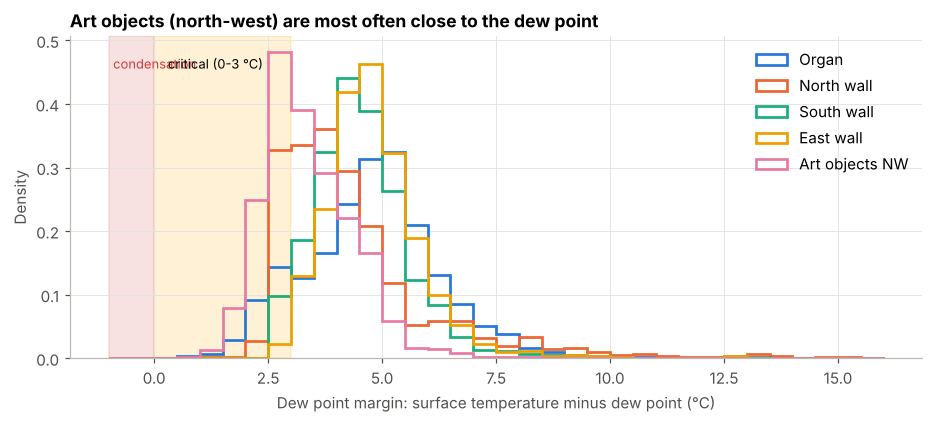

readings with condensation (margin <= 0): 3
                          location  surf_temp  dew_point  margin  air_rh
time                                                                    
2024-11-06 14:20:00+01:00       O1      10.04      10.08   -0.04   80.37
2024-11-06 14:40:00+01:00       O1      10.17      10.18   -0.01   80.14
2024-11-06 15:00:00+01:00       O1      10.21      10.24   -0.03   79.82


In [2]:
rows = []
for s in C.SURFACE_SENSORS:
    m = feat.loc[feat.location == s, "margin"].dropna()
    rows.append({"location": P.name(s), "valid hours": len(m) / 3, "min margin (°C)": m.min(),
                 "median (°C)": m.median(), "≤ 0 °C (condensation)": (m <= 0).mean(),
                 "0-2 °C": ((m > 0) & (m <= 2)).mean(), "0-3 °C (critical)": ((m > 0) & (m <= 3)).mean(),
                 "0-4 °C": ((m > 0) & (m <= 4)).mean(), "> 3 °C (safer)": (m > 3).mean()})
margin_tab = pd.DataFrame(rows).set_index("location")
display(margin_tab.style.format({c: "{:.1%}" for c in margin_tab.columns if "°C" in c and "(°C)" not in c}
                                | {"valid hours": "{:.0f}", "min margin (°C)": "{:.2f}", "median (°C)": "{:.2f}"}))
results.save_table(margin_tab.round(4), "dew_point_margin")

fig, ax = plt.subplots(figsize=(10, 3.8))
edges = np.arange(-1, 16.5, 0.5)
for s in C.SURFACE_SENSORS:
    m = feat.loc[feat.location == s, "margin"].dropna()
    ax.hist(m, bins=edges, histtype="step", lw=1.8, density=True, label=P.name(s), color=P.LOCATION_COLORS[s])
ax.axvspan(-1, 0, color=P.STATUS["high"], alpha=0.15)
ax.axvspan(0, 3, color=P.STATUS["medium"], alpha=0.18)
ax.text(-0.9, ax.get_ylim()[1] * 0.9, "condensation", color=P.STATUS["high"], fontsize=8.5)
ax.text(0.3, ax.get_ylim()[1] * 0.9, "critical (0-3 °C)", fontsize=8.5)
ax.set_xlabel("Dew point margin: surface temperature minus dew point (°C)"); ax.set_ylabel("Density")
ax.set_title("Art objects (north-west) are most often close to the dew point")
ax.legend()
P.save(fig, "03_margin_hist.png"); plt.show()

cond = feat[(feat.margin <= 0)]
print("readings with condensation (margin <= 0):", len(cond))
print(cond[["location", "surf_temp", "dew_point", "margin", "air_rh"]].round(2).head(10))
results.update(n_condensation=len(cond),
               margin_critical_share={P.name(s): float(margin_tab.loc[P.name(s), "0-3 °C (critical)"]) for s in C.SURFACE_SENSORS})

**Decision:** true condensation (margin ≤ 0) is extremely rare (3 organ readings on
6 Nov 2024), so condensation alone would declare every location "safe". The **0–3 °C
critical band** is what separates the locations: the north-west art objects spend about
40 % of their valid time there, the north wall 18 %, the organ 14 %, the south and east
walls 5 % and 1 %. With a 2 °C or 4 °C limit the shares change strongly (2 °C: almost
nothing is critical; 4 °C: half of the north wall readings), but the art objects stay
first and the north wall stays above the south and east walls. Only the organ moves
within the middle of the order. 3 °C stays the default (brief, common practice), and
2 / 4 °C are carried into the sensitivity analysis of the risk index (notebook 04).

## 2 · Temperature-dependent humidity limit (LIM)

Approximate points read from Figure 2 of the brief and interpolated linearly
(`src/config.py`). Class I (biologically degradable: dust, dirt, wallpaper) is the
default because surfaces in a church are dusty; class II (mineral building materials)
is the less strict comparison. *Values are read visually and therefore approximate
(±1 % relative humidity).*

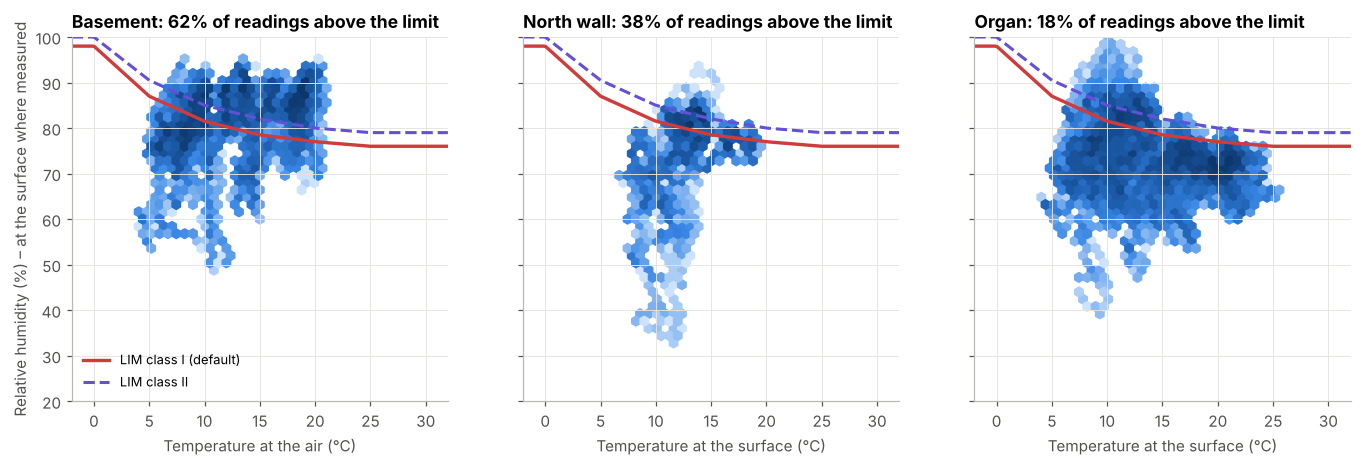

,above LIM I (surface basis),above LIM II (surface basis),above LIM I (room air basis),mean LIM excess I (%-points)
Organ,0.176,0.077,0.070,-6.228
North wall,0.385,0.112,0.272,-4.795
South wall,0.209,0.029,0.175,-4.782
East wall,0.126,0.007,0.103,-5.909
Art objects NW,0.541,0.328,0.537,-0.518
Art objects S,0.239,0.114,0.239,-7.959
Attic,0.194,0.104,0.194,-12.793
Basement,0.621,0.487,0.621,1.501


In [3]:
tt = np.linspace(-2, 32, 200)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
for ax, s in zip(axes, ["Ke1", "AWn", "O1"]):
    f = feat[feat.location == s].dropna(subset=["ref_rh"])
    hb = ax.hexbin(f["ref_temp"], f["ref_rh"], gridsize=45, cmap=P.SEQ_BLUE, mincnt=1, bins="log", extent=(-2, 32, 20, 100))
    ax.plot(tt, lim_threshold(tt, "I"), color=P.STATUS["high"], lw=2.2, label="LIM class I (default)")
    ax.plot(tt, lim_threshold(tt, "II"), color="#6250d6", lw=2, ls="--", label="LIM class II")
    share = (f["lim_excess"] > 0).mean()
    basis = "surface" if s in C.SURFACE_SENSORS else "air"
    ax.set_title(f"{P.name(s)}: {share:.0%} of readings above the limit")
    ax.set_xlabel(f"Temperature at the {basis} (°C)")
    ax.set_xlim(-2, 32); ax.set_ylim(20, 100)
axes[0].set_ylabel("Relative humidity (%) – at the surface where measured")
axes[0].legend(loc="lower left", fontsize=8.5)
P.save(fig, "03_lim_scatter.png"); plt.show()

feat2 = build_features(df, lim_class="II", with_duration=False)
air = build_features(df, basis="air", with_duration=False)
lim_tab = pd.DataFrame({
    "above LIM I (surface basis)": feat.groupby("location", observed=True)["crit_lim"].mean(),
    "above LIM II (surface basis)": feat2.groupby("location", observed=True)["crit_lim"].mean(),
    "above LIM I (room air basis)": air.groupby("location", observed=True)["crit_lim"].mean(),
    "mean LIM excess I (%-points)": feat.groupby("location", observed=True)["lim_excess"].mean(),
}).round(3)
lim_tab.index = [P.name(s) for s in lim_tab.index]
display(lim_tab)
results.save_table(lim_tab, "lim_shares")

**Decision:** the basement and the north-west art objects exceed the class I limit
for a large part of the time; class II roughly halves the shares but keeps the order.
Class I stays the default (conservative, appropriate for dusty surfaces and art
objects). The surface basis raises the shares compared with room air at the organ and
the north wall, because their surfaces are colder than the air (next section).

## 3 · Surface relative humidity

With the dew point of the room air $T_d$ and the surface temperature $T_s$ (Magnus):
$RH_s = 100 \cdot e_s(T_d) / e_s(T_s)$, with $e_s(T) = 6.112 \cdot \exp\left(\frac{17.62\,T}{243.12 + T}\right)$.

In [4]:
srh = pd.DataFrame({
    "surface − air temp (°C), mean": [feat.loc[feat.location == s, "surf_minus_air"].mean() for s in C.SURFACE_SENSORS],
    "surface − air temp, winter (DJF)": [feat.loc[(feat.location == s) & feat.month.isin([12, 1, 2]), "surf_minus_air"].mean() for s in C.SURFACE_SENSORS],
    "surface RH − air RH (%-points), mean": [(feat.loc[feat.location == s, "surf_rh"] - feat.loc[feat.location == s, "air_rh"]).mean() for s in C.SURFACE_SENSORS],
    "max surface RH (%)": [feat.loc[feat.location == s, "surf_rh"].max() for s in C.SURFACE_SENSORS],
}, index=[P.name(s) for s in C.SURFACE_SENSORS]).round(2)
display(srh)
results.save_table(srh, "surface_rh")

,"surface − air temp (°C), mean","surface − air temp, winter (DJF)","surface RH − air RH (%-points), mean",max surface RH (%)
Organ,-0.65,-1.55,3.12,100.00
North wall,-0.40,-0.53,1.84,92.78
South wall,-0.14,-0.34,0.67,85.12
East wall,-0.13,-0.31,0.57,88.34
Art objects NW,-0.09,-0.33,0.47,97.47


**Decision:** surfaces are on average 0.1–0.7 °C colder than the air (most at the organ
and the north wall), which raises the humidity at the surface by up to several
percentage points. Mold grows on surfaces, so wherever a surface sensor exists, the LIM
comparison uses the **surface relative humidity** at the **surface temperature**. For
the attic, basement and south art objects only room air is available (a limitation:
their surfaces may be colder still).

## 4 · Duration features

The per-reading flag `crit_lim` is 1 (above LIM), 0 (below) or **NaN when data is
missing**. Rolling windows count critical hours and divide by the *valid* hours in the
window; with less than 50 % valid data in the window the share is NaN.

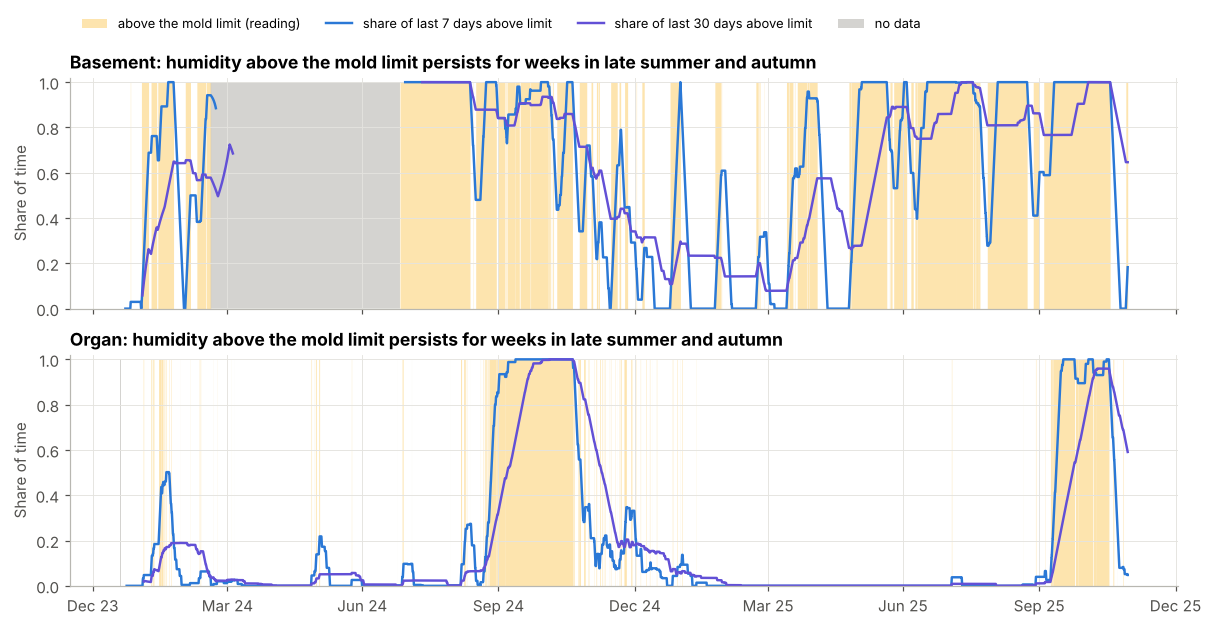

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
for ax, s in zip(axes, ["Ke1", "O1"]):
    f = feat[feat.location == s]
    ax.fill_between(f.index, 0, f["crit_lim"].fillna(0), step="post", color=P.STATUS["medium"], alpha=0.35, lw=0,
                    label="above the mold limit (reading)")
    ax.plot(f.index, f["crit_lim_share_7D"], color=P.SERIES[0], label="share of last 7 days above limit")
    ax.plot(f.index, f["crit_lim_share_30D"], color=P.SERIES[6], label="share of last 30 days above limit")
    miss = f["crit_lim"].isna()
    ax.fill_between(f.index, 0, 1, where=miss, color=P.STATUS["unknown"], alpha=0.6, lw=0, label="no data")
    ax.set_ylabel("Share of time"); ax.set_ylim(0, 1.02)
    ax.set_title(f"{P.name(s)}: humidity above the mold limit persists for weeks in late summer and autumn")
axes[0].legend(ncol=4, fontsize=8.5, loc="upper left", bbox_to_anchor=(0, 1.32))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
P.save(fig, "03_duration.png"); plt.show()

,valid hours,critical hours (cumulative),critical share,episodes above LIM,episodes ≥ 24 h,longest episode (days),median episode (h),max 30-day share
location,,,,,,,,
Organ,16302.67,2871.33,0.18,146,12,45.65,2.33,1.00
North wall,2713.67,1044.00,0.38,58,9,12.64,0.67,0.90
South wall,8797.00,1838.67,0.21,137,18,8.96,0.67,0.92
East wall,8110.33,1019.67,0.13,113,10,7.10,1.00,0.57
Art objects NW,10242.67,5542.33,0.54,147,34,44.83,2.67,1.00
Art objects S,16323.33,3904.00,0.24,316,30,7.81,8.00,0.92
Attic,15819.33,3069.00,0.19,233,32,7.21,4.67,0.82
Basement,13256.33,8229.67,0.62,86,41,47.26,17.17,1.00


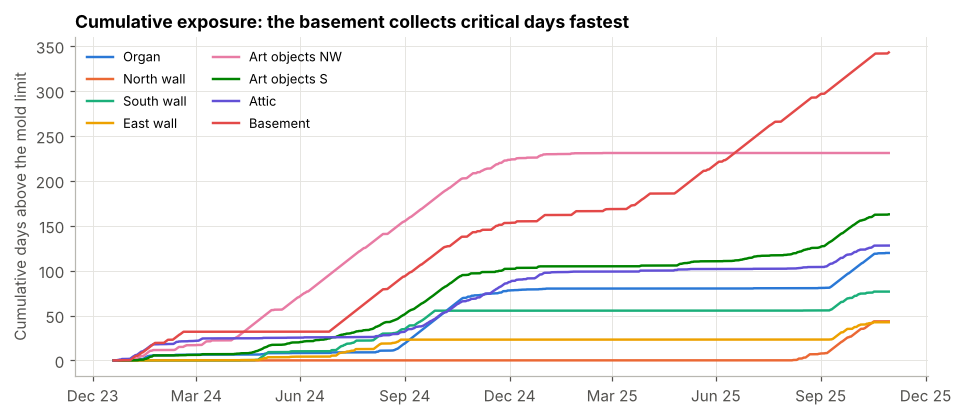

In [6]:
rows = []
for s in C.INDOOR:
    f = feat[feat.location == s]
    ep = episodes(f["crit_lim"])
    rows.append({"location": P.name(s), "valid hours": f["crit_lim"].notna().sum() / 3,
                 "critical hours (cumulative)": f["crit_lim_cum_h"].iloc[-1],
                 "critical share": f["crit_lim"].mean(),
                 "episodes above LIM": len(ep), "episodes ≥ 24 h": int((ep.duration_h >= 24).sum()),
                 "longest episode (days)": ep.duration_h.max() / 24 if len(ep) else 0,
                 "median episode (h)": ep.duration_h.median() if len(ep) else 0,
                 "max 30-day share": f["crit_lim_share_30D"].max()})
dur = pd.DataFrame(rows).set_index("location").round(2)
display(dur)
results.save_table(dur, "duration_features")

fig, ax = plt.subplots(figsize=(10, 4))
for s in C.INDOOR:
    f = feat[feat.location == s]
    ax.plot(f.index, f["crit_lim_cum_h"] / 24, label=P.name(s), color=P.LOCATION_COLORS[s])
ax.set_ylabel("Cumulative days above the mold limit"); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
ax.set_title("Cumulative exposure: the basement collects critical days fastest")
ax.legend(ncol=2, fontsize=8.5)
P.save(fig, "03_cumulative.png"); plt.show()

**Decision:** many short excursions above the limit last only a few hours (median
episode length is short), but some locations have episodes lasting several days to weeks.
Following the guideline (duration matters more than single peaks), the risk index in
notebook 04 uses a **7-day window**: humidity above LIM that persists for at least half
of the valid time in the last 7 days is treated as high risk. Episodes and cumulative
exposure are reported per location.

## 5 · Cross-sensor and time features: when can ventilation help?

Ventilation only dries a room when the outside air contains **less water per m³** than
the inside air (absolute humidity), whatever the relative humidity outside says. We
count the time when the outside air is drier by more than 0.5 g/m³ (a margin for sensor
uncertainty; the outside humidity sensor saturates in fog).

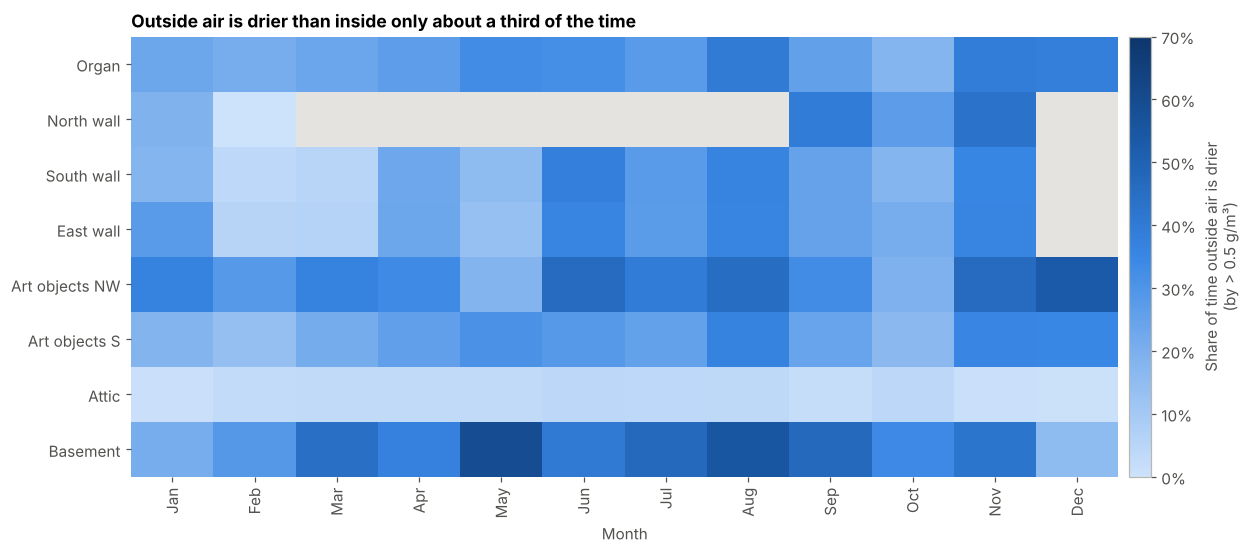

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
O1,0.233355,0.209308,0.236748,0.265278,0.330421,0.319907,0.276434,0.39536,0.255781,0.178971,0.387417,0.382616
AWn,0.187919,0.000903,NaN,NaN,NaN,NaN,NaN,NaN,0.393246,0.270246,0.430851,NaN
AWs,0.180089,0.039751,0.050247,0.228704,0.155018,0.379213,0.274194,0.361111,0.247998,0.179195,0.352515,NaN
AWo,0.275168,0.052203,0.058771,0.230556,0.135305,0.359722,0.272401,0.360663,0.24783,0.205369,0.359768,NaN
K1,0.365003,0.281155,0.368354,0.338321,0.1819,0.463889,0.391129,0.455645,0.330093,0.192394,0.464815,0.527778
K2,0.181062,0.138158,0.21159,0.257639,0.3069,0.283333,0.254032,0.368213,0.241065,0.166667,0.354778,0.349014
D1,0.009277,0.025341,0.030997,0.030556,0.03181,0.04213,0.040099,0.037819,0.020477,0.042336,0.007486,0.003136
Ke1,0.205374,0.287037,0.443956,0.374074,0.59095,0.400926,0.470118,0.54942,0.46975,0.33915,0.421712,0.150986


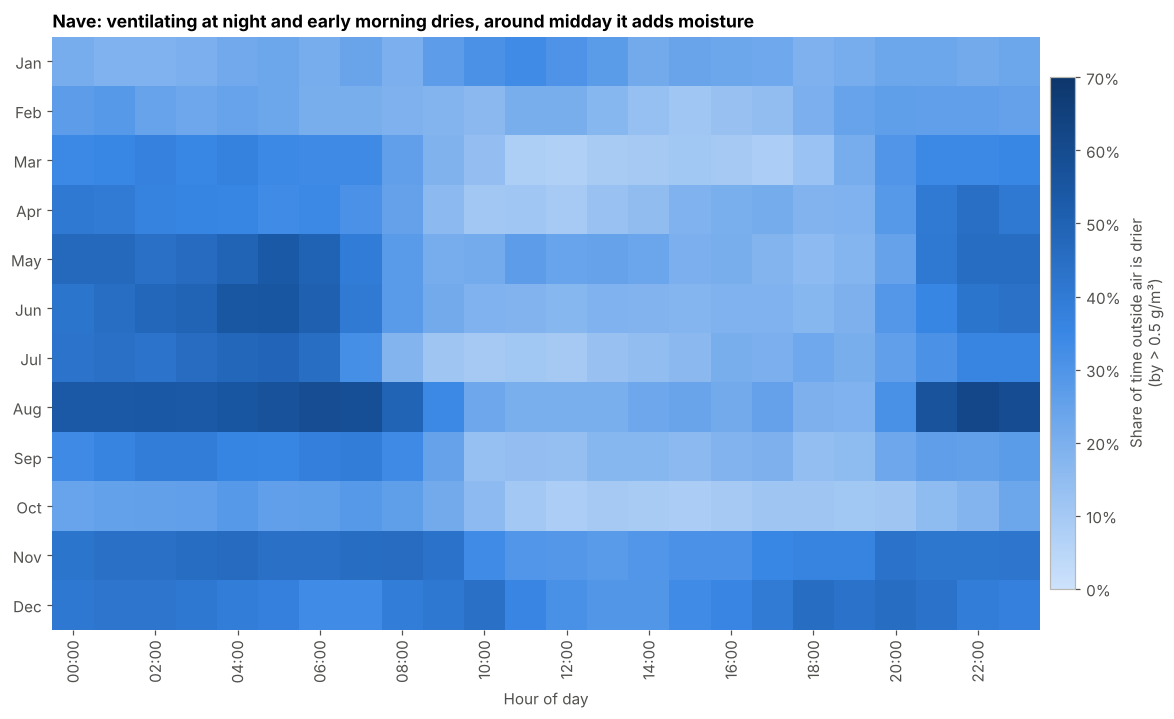

nave: outside drier at night (0-7 h) 39% vs midday (11-17 h) 18%; May-Aug: night 49% vs midday 19%


In [7]:
def drier_outside(f):
    d = f["d_abs_hum_in_out"]
    return (d > 0.5).where(d.notna())

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
vent = pd.DataFrame({s: drier_outside(feat[feat.location == s]).groupby(feat.loc[feat.location == s].month).mean()
                     for s in C.INDOOR})
vent.index = months
fig, ax = P.calendar_heatmap(vent, "Outside air is drier than inside only about a third of the time",
                             "Share of time outside air is drier\n(by > 0.5 g/m³)", cmap=P.SEQ_BLUE, vmax=0.7)
ax.set_xlabel("Month")
P.save(fig, "03_ventilation_potential.png"); plt.show()
display(vent.round(2).T)
results.save_table(vent.round(3), "ventilation_potential")

fo = feat[feat.location == "O1"]
hv = drier_outside(fo).groupby([fo.month, fo.hour]).mean().unstack(0)
hv.columns = months
hv.index = [f"{h:02d}:00" for h in hv.index]
fig, ax = P.calendar_heatmap(hv, "Nave: ventilating at night and early morning dries, around midday it adds moisture",
                             "Share of time outside air is drier\n(by > 0.5 g/m³)", cmap=P.SEQ_BLUE, vmax=0.7)
ax.set_yticks(range(len(months)), months); ax.set_xlabel("Hour of day")
ax.set_xticks(range(0, 24, 2), hv.index[::2], rotation=90)
P.save(fig, "03_ventilation_hour.png"); plt.show()
night = drier_outside(fo)[fo.hour.isin(range(0, 7))].mean()
midday = drier_outside(fo)[fo.hour.isin(range(11, 17))].mean()
night_summer = drier_outside(fo)[fo.hour.isin(range(0, 7)) & fo.month.isin([5, 6, 7, 8])].mean()
midday_summer = drier_outside(fo)[fo.hour.isin(range(11, 17)) & fo.month.isin([5, 6, 7, 8])].mean()
print(f"nave: outside drier at night (0-7 h) {night:.0%} vs midday (11-17 h) {midday:.0%}; "
      f"May-Aug: night {night_summer:.0%} vs midday {midday_summer:.0%}")
results.update(vent_night=night, vent_midday=midday, vent_night_summer=night_summer, vent_midday_summer=midday_summer,
               vent_basement_mean=float(drier_outside(feat[feat.location == "Ke1"]).mean()))

**Decision:** the inside absolute humidity follows the outside closely (the church is
well coupled to the outside air and has no strong internal moisture source, notebook 02).
There is **no season in which ventilation reliably dries**: outside air is drier only
20–50 % of the time. The timing *within the day* matters much more: in May–August the
outside air is drier about half of the time at night and early morning but rarely around
midday, when warm humid air would enter the cool church and raise the humidity at cold
surfaces. The basement is the location where outside air is most often drier, which hints
at a moisture source in the basement (ground moisture). Recommendation: **ventilate
only when the outside absolute humidity is lower than inside**, in practice at night and
in the early morning, ideally controlled automatically by a humidity-difference switch.

## 6 · Save the feature table

In [8]:
feat.to_parquet(C.FEATURES_FILE)
print("saved", C.FEATURES_FILE.relative_to(ROOT), feat.shape)
print("features:", [c for c in feat.columns if c != "location"])

saved data/processed/features.parquet (391768, 33)
features: ['air_temp', 'air_rh', 'dew_point', 'abs_hum', 'surf_temp', 'margin', 'surf_rh', 'surf_minus_air', 'ref_temp', 'ref_rh', 'lim', 'lim_excess', 'crit_lim', 'condensation', 'crit_margin', 'd_temp_in_out', 'd_abs_hum_in_out', 'interpolated', 'crit_lim_h_24h', 'crit_lim_share_24h', 'crit_lim_h_7D', 'crit_lim_share_7D', 'crit_lim_h_30D', 'crit_lim_share_30D', 'crit_lim_cum_h', 'crit_lim_cum_valid_h', 'hour', 'month', 'weekday', 'is_sunday', 'season', 'heating_season']
